# Airbnb Madrid: clasificación del tipo de alojamiento con árbol de decisión, KNN y Naive Bayes

El objetivo de este análisis es emplear el conjunto de datos "airbnb.csv" para predecir la variable *room_type* a partir del resto de características disponibles. Estos datos recogen información sobre ofertas de alquiler de alojamientos de Airbnb en Madrid en 2017.

Para llevarlo a cabo, en primer lugar se realizará una exploración inicial de los datos junto con un análisis descriptivo de las variables, con el objetivo de comprender su estructura y principales características. En esta etapa se identificarán posibles valores nulos, valores atípicos (outliers) y relaciones entre variables. Posteriormente, se efectuará la limpieza de los datos en función de lo observado.

Después se dividirán los datos en entrenamiento (80%) y prueba (20%). El conjunto de entrenamiento es el que emplearemos para entrenar el modelo y el conjunto de prueba le reservaremos para evaluar el modelo una vez ya esté entrenado.

El siguiente paso será el entrenamiento de tres algoritmos de clasificación supervisada:

* Árbol de Decisión
* K-Nearest Neighbors (KNN)
* Naive Bayes

Se evaluará el rendimiento de los distintos modelos mediante validación cruzada con 10 particiones, teniendo en cuenta la precisión (accuracy). Para KNN y Árbol de Decisión se realizará una afinación de hiperparámetros empleando GridSearchCV.

Tras este proceso, se evaluarán los modelos finales sobre el conjunto de prueba y se compararán los resultados obtenidos para determinar qué modelo ofrece el mejor rendimiento a la hora de predecir la variable objetivo *room_type*.



**LIBRERÍAS**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder, MinMaxScaler, OrdinalEncoder, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
import warnings
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB, CategoricalNB
from tabulate import tabulate
from sklearn.model_selection import GridSearchCV
from sklearn.tree import export_graphviz
from graphviz import Source
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, confusion_matrix


In [3]:
warnings.filterwarnings('ignore')

**CARGA DE LOS DATOS**

In [4]:
alquileres = pd.read_csv('data/airbnb.csv')

**EXPLORACIÓN INICIAL Y ANÁLISIS DESCRIPTIVO DE LAS VARIABLES**

Una vez cargados los datos, es importante examinarlos y entender qué tipo de variables y problemas existen en ellos para identificar aspectos relevantes a tener en cuenta después. Para ello, se realiza un breve análisis exploratorio de los datos.

In [5]:
alquileres.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Centro,Justicia,40.424715,-3.698638,Entire home/apt,49,28,35,0.42,1,99
1,Centro,Embajadores,40.413418,-3.706838,Entire home/apt,80,5,18,0.30,1,188
2,Moncloa - Aravaca,Argüelles,40.424920,-3.713446,Entire home/apt,40,2,21,0.25,9,195
3,Moncloa - Aravaca,Casa de Campo,40.431027,-3.724586,Entire home/apt,55,2,3,0.13,9,334
4,Latina,Cármenes,40.403410,-3.740842,Private room,16,2,23,0.76,2,250


Cada fila representa una oferta de alquiler y en total tenemos información acerca de 11 variables (la variable objetivo *room_type* y 10 variables explicativas relacionadas con las ofertas), que contienen la siguiente información:


*   *neighbourhood_group* : distrito en el que se ubica el alojamiento
*   *neighbourhood* : barrio en el que se ubica el alojamiento
*   *latitude* : latitud del alojamiento
*   *longitude* : longitud del alojamiento
*   *room_type* : tipo de habitación
*   *price* : precio por noche
*   *minimum_nights* : mínimo de noches
*   *number_of_reviews* : número de reseñas
*   *reviews_per_month* : reseñas por mes
*   *calculated_host_listings_count* : número de propiedades del anfitrión
*   *availability_365* : disponibilidad del alojamiento (en días) en 1 año

















In [6]:
alquileres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13321 entries, 0 to 13320
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             13321 non-null  object 
 1   neighbourhood                   13321 non-null  object 
 2   latitude                        13321 non-null  float64
 3   longitude                       13321 non-null  float64
 4   room_type                       13321 non-null  object 
 5   price                           13321 non-null  int64  
 6   minimum_nights                  13321 non-null  int64  
 7   number_of_reviews               13321 non-null  int64  
 8   reviews_per_month               13321 non-null  float64
 9   calculated_host_listings_count  13321 non-null  int64  
 10  availability_365                13321 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 1.1+ MB


Observamos que hay un total de 13321 ofertas y que ninguna de las 11 variables presenta valores nulos. Además, de estas 11 variables, 8 son numéricas y 3 son categóricas, siendo una de ellas la variable objetivo *room_type*. Por esta razón, como se mencionó anteriormente, se utilizarán modelos de clasificación y no de regresión.

**Variables numéricas**

En las siguientes celdas se visualiza un resumen de diferentes medidas estadísticas de las variables numéricas junto con sus histogramas.

In [7]:
alquileres.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000
mean,40.420730,-3.697268,69.171834,3.010885,22.986037,1.520329,7.605885,205.867202
std,0.020344,0.023832,103.721126,12.835619,38.406006,1.852367,19.619972,126.968961
min,40.331888,-3.863907,9.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,40.410090,-3.707856,31.000000,1.000000,1.000000,0.110000,1.000000,84.000000
50%,40.418731,-3.701602,53.000000,2.000000,7.000000,0.780000,2.000000,247.000000
75%,40.427997,-3.693818,80.000000,3.000000,28.000000,2.320000,4.000000,321.000000
max,40.562736,-3.526821,7700.000000,1125.000000,446.000000,17.210000,145.000000,365.000000


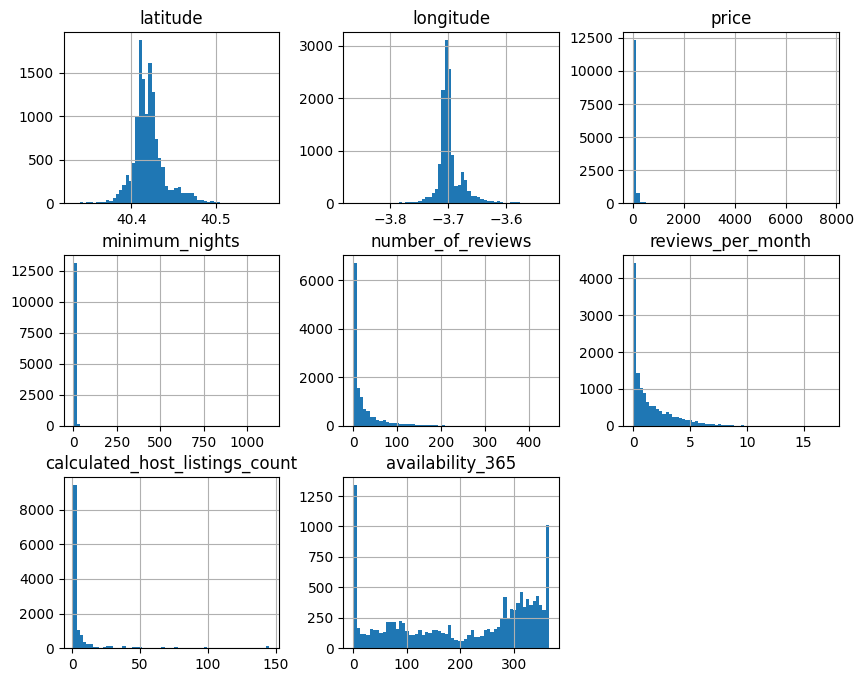

In [8]:
alquileres.hist(bins=60, figsize=(10, 8))
plt.show()

Las variables *latitude* y *longitude* se distribuyen de forma aproximadamente simétrica, con una dispersión muy baja, indicando que los alojamientos se concentran en una misma zona.

En cambio, las variables *price*, *minimum_nights*, *number_of_reviews*, *reviews_per_month*, *calculated_host_listings_count* muestran histogramas con distribuciones asimétricas positivas (reflejado en la diferencia existente entre la media y la mediana) y tienen alta dispersión, con gran parte de los valores cerca de 0. En todas ellas se observan valores atípicos/outliers, ya que los valores máximos están muy alejados del percentil 75.

Por último, en *availability_365* se observan 2 modas (picos) en los extremos, indicando que gran parte de los alojamientos no están disponibles durante todo el año o están disponibles la mayor parte del tiempo.


Otro aspecto a destacar es que las variables se miden en escalas numéricas muy diferentes (por ejemplo, *price* en €, *minimum_nights* en días, etc), por lo que será necesario aplicar algún tipo de escalado más adelante.

**Variables categóricas**

A continuación, examinamos los recuentos de cada clase de las tres variables categóricas, empezando por la variable objetivo.

In [9]:
alquileres["room_type"].value_counts()

,count
room_type,
Entire home/apt,7926
Private room,5203
Shared room,192


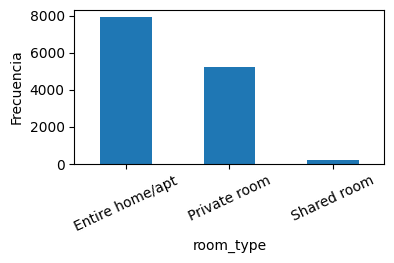

In [10]:
plt.figure(figsize=(4,2))
alquileres['room_type'].value_counts().plot(kind='bar')

plt.ylabel('Frecuencia')
plt.xticks(rotation=25)
plt.show()

La variable objetivo *room_type* presenta tres categorías: Entire home/apt (7926 filas), Private room (5203) y Shared room (192).

Se aprecia un desbalance entre las categorías, ya que la mayoría de las ofertas son de apartamentos enteros, mientras que las habitaciones compartidas son muy poco frecuentes. Esta característica habrá que tenerla en cuenta en la creación de los modelos.

Por último, observamos las categorías de las otras dos variables, relacionadas con los distritos y los barrios:

In [11]:
alquileres["neighbourhood_group"].value_counts()

,count
neighbourhood_group,
Centro,6773
Chamberí,960
Salamanca,883
Arganzuela,790
Tetuán,463
Moncloa - Aravaca,450
Retiro,439
Latina,379
Chamartín,361


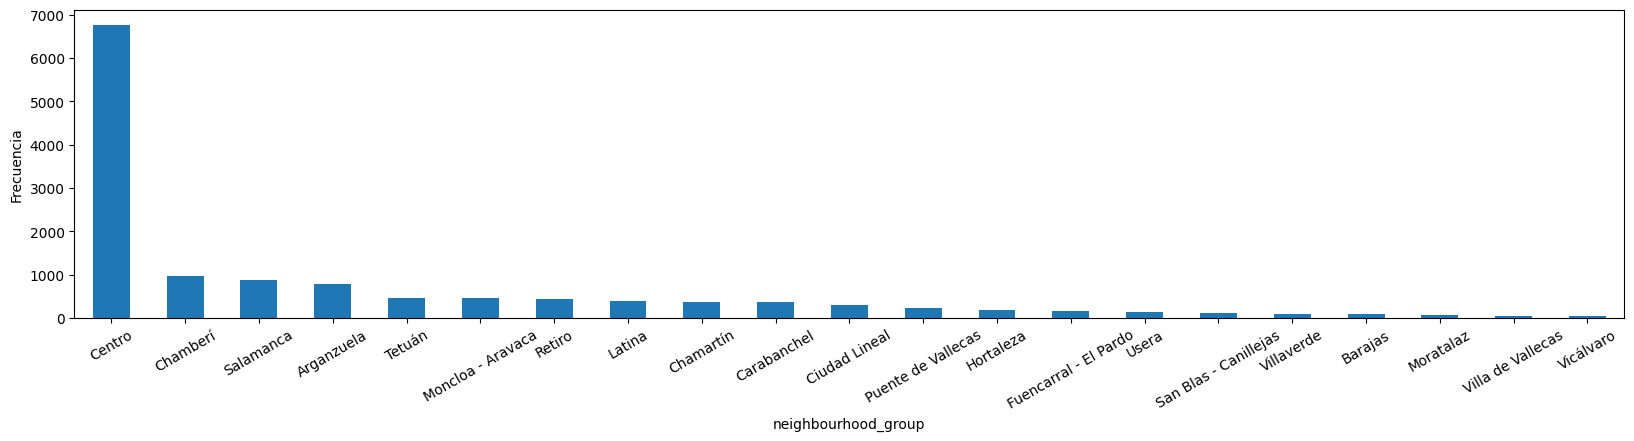

In [12]:
plt.figure(figsize=(20,4))
alquileres['neighbourhood_group'].value_counts().plot(kind='bar')
plt.ylabel('Frecuencia')
plt.xticks(rotation=30)
plt.show()

In [13]:
alquileres["neighbourhood"].value_counts()

,count
neighbourhood,
Embajadores,1848
Universidad,1363
Palacio,1084
Sol,942
Justicia,788
...,...
El Goloso,4
Pavones,4
Cuatro Vientos,3


Tanto en *neighbourhood* como en *neighbourhood_group* se deja ver que en el distrito Centro y en los barrios pertenecientes a este distrito (Embajadores, Universidad, Palacio, Sol, Justicia), se concentran las ofertas de alquiler mayoritariamente.

El resto de distritos y barrios presentan mucha menor proporción de ofertas e incluso en barrios como Orcasitas o El Pardo apenas hay ofertas.

Esta distribución tiene sentido al tratarse de apartamentos turísticos, ya que en el distrito Centro se concentra la mayor parte de los puntos de interés. Por ello, las ofertas de alojamientos se ubican en él principalmente.

**Valores atípicos/outliers**

En los histogramas hemos detectado posibles outliers, por lo que vamos a dibujar diagramas de caja (boxplots) para detectar las observaciones que se alejan del rango intercuartílico (IQR=Q3-Q1).

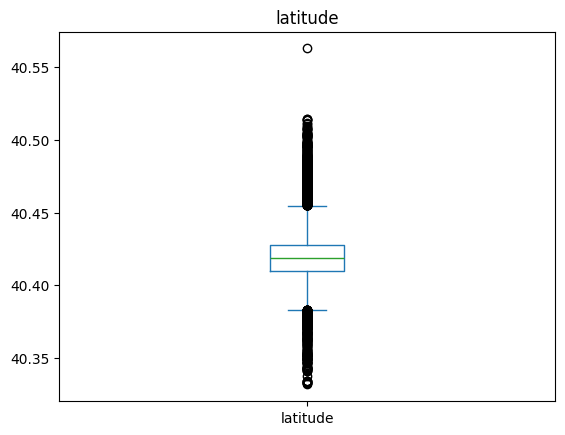

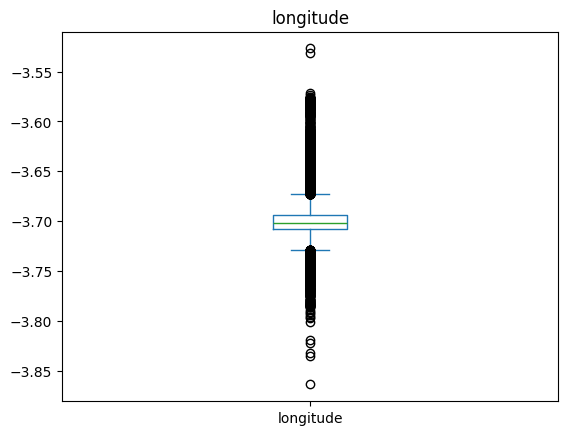

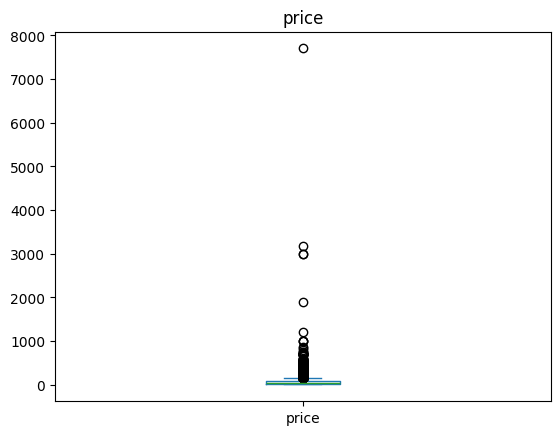

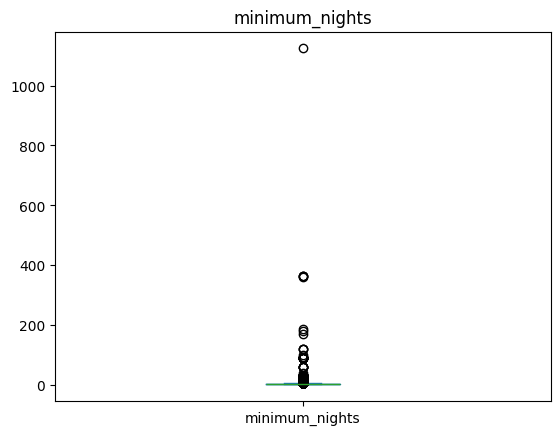

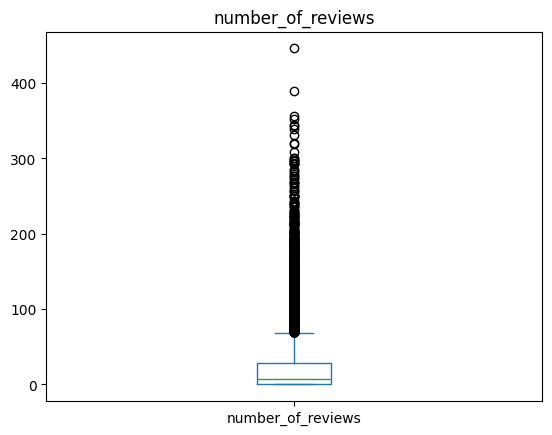

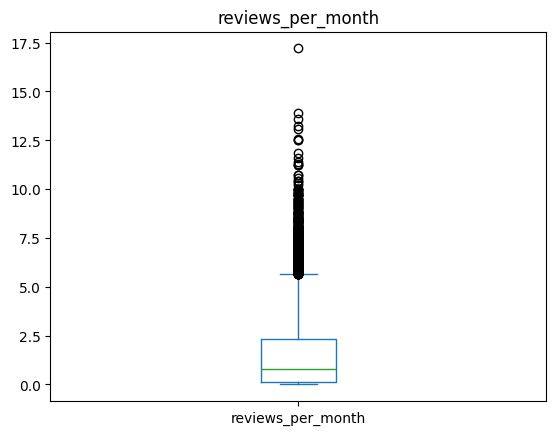

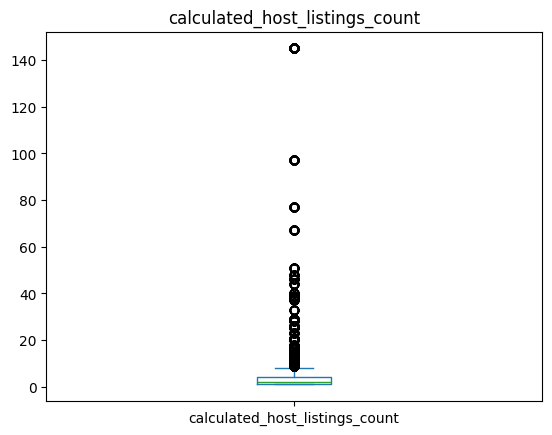

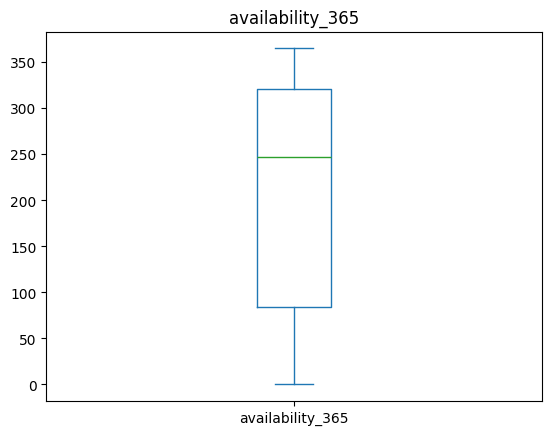

In [14]:
numeric_cols = ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month',
                'calculated_host_listings_count', 'availability_365']

for col in numeric_cols:
    if col in alquileres.columns:
        plt.figure()
        alquileres[col].plot.box()
        plt.title(col)
        plt.show()

En las variables *latitude* y *longitude* se observan numerosos valores que se encuentran fuera del rango intercuartílico, debido a que la mayoría de las coordenadas se concentran en un rango muy reducido (ya hemos visto que predominan las ofertas en el distrito Centro), haciendo que las zonas más alejadas puedan parecer outliers. En cambio, no parecen datos erróneos sino ubicaciones distantes del centro.

Las variables *price*, *minimum_nights*, *number_of_reviews*, *reviews_per_month* y *calculated_host_listings_count* están bastante sesgadas debido a la concentración de valores pequeños. Para intentar corregirlo aplicaremos transformaciones logarítmicas.


Además, en *price* se observan valores extremos por encima de 3000€/noche y un valor máximo cerca de 7700€.
Dado que tenemos suficiente número de filas y que estos precios tan extremos son altamente sospechosos, vamos a eliminar los precios superiores a 2000€/noche. De esta forma, evitamos sesgos relacionados con estos valores.

Por otro lado, en *minimum_nights* la mayoría de los alquileres tienen un mínimo de 1-2 noches. En esta variable también hay outliers muy extremos, alcanzando más de 400 y el máximo de 1125 noches (más de 3 años). Eliminaremos los valores superiores a 1 año, ya que carecen de sentido valores tan extremos teniendo en cuenta que se trata de alquileres vacacionales.

 De manera similar, las variables *number_of_reviews*, *reviews_per_month* y *calculated_host_listings_count* presentan gran cantidad de outliers. En cambio, a diferencia de *price* y *minimum_nights* pueden tener sentido, ya que puede haber unos pocos alojamientos con muchas reseñas en comparación con la mediana y unos pocos anfitriones con muchas propiedades. Por tanto, para estas tres variables vamos a mantener todos los casos.

Por último, la variable *availability_365* tiene una amplitud de la caja muy grande debido a la distribución bimodal con datos en los extremos que vimos que la caracterizaba. En este caso, no observamos valores atípicos.

En las siguientes celdas eliminamos los extremos comentados de *price* y *minimum_nigths*, a la vez que realizamos transformaciones logarítmicas a las variables que están sesgadas.
Para *number_of_reviews* y *reviews_per_month* aplicamos el logaritmo del valor de la variable + 1 (log1p), ya que observando el resumen de medidas estadísticas vemos que hay valores 0 y no existe el logaritmo de 0. Para el resto de variables no haría falta al no haber ceros.

In [15]:
alquileres = alquileres[alquileres['price'] <= 2000]
alquileres = alquileres[alquileres['minimum_nights'] <= 365]

In [16]:
alquileres['log_price'] = np.log(alquileres['price'])
alquileres['log_minimum_nights'] = np.log(alquileres['minimum_nights'])
alquileres['log_number_of_reviews'] = np.log1p(alquileres['number_of_reviews'])
alquileres['log_reviews_per_month'] = np.log1p(alquileres['reviews_per_month'])
alquileres['log_calculated_host_listings_count'] = np.log(alquileres['calculated_host_listings_count'])

Observamos cómo se distribuyen las variables tras aplicar las transformaciones:

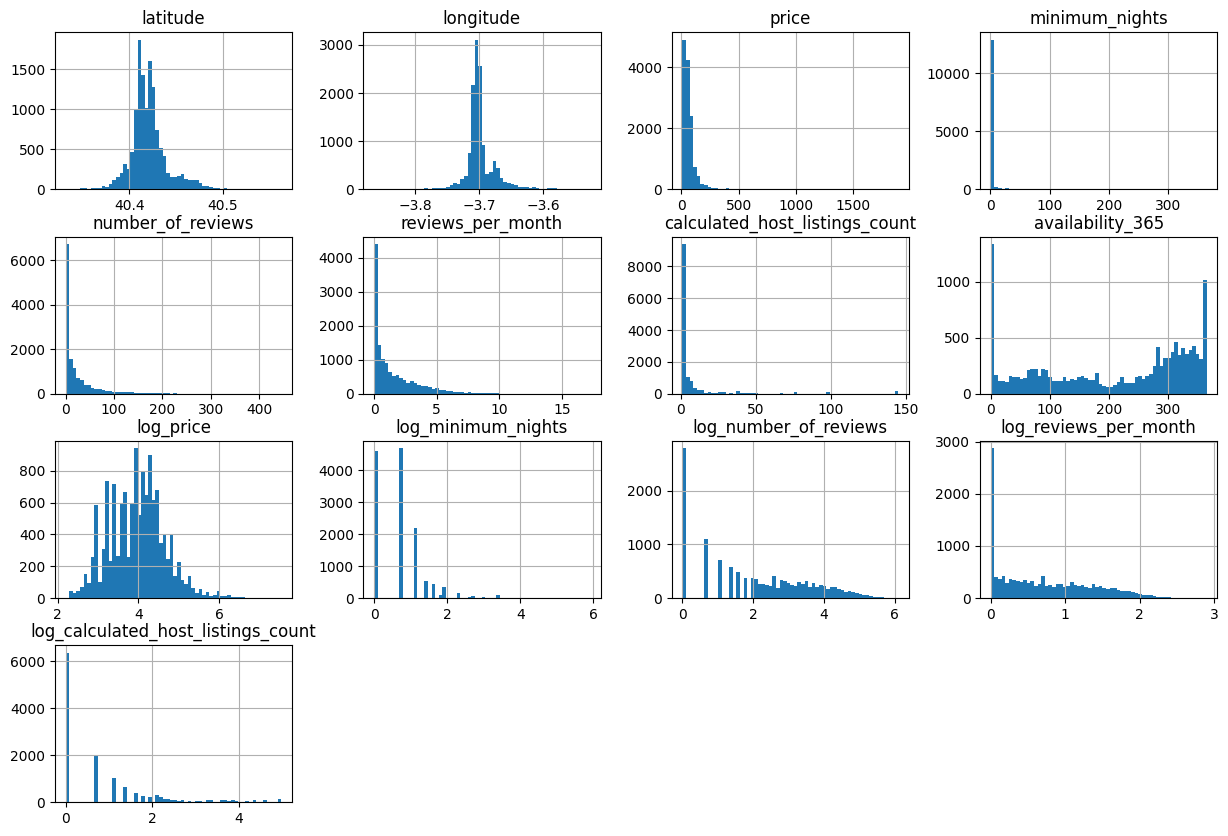

In [17]:
alquileres.hist(bins=60, figsize=(15, 10))
plt.show()

En *log_price* se ve que la transformación logarítmica ha sido muy efectiva, ya que se consigue mejorar significativamente la simetría de su distribución, aproximándola a una normal. Sin embargo, el resto de variables siguen estando bastante sesgadas, debido a la gran concentración de valores muy bajos.

**Correlaciones entre variables**

Para ver las posibles relaciones entre las variables explicativas vamos a calcular la matriz de correlaciones y a visualizar algunos gráficos de dispersión de las variables que pueden estar más relacionadas entre sí.

In [18]:
numeric_cols_con_log = ['latitude', 'longitude','log_price', 'log_minimum_nights', 'log_number_of_reviews',
            'log_reviews_per_month', 'log_calculated_host_listings_count', 'availability_365']

corr_matrix = alquileres[numeric_cols_con_log].corr()

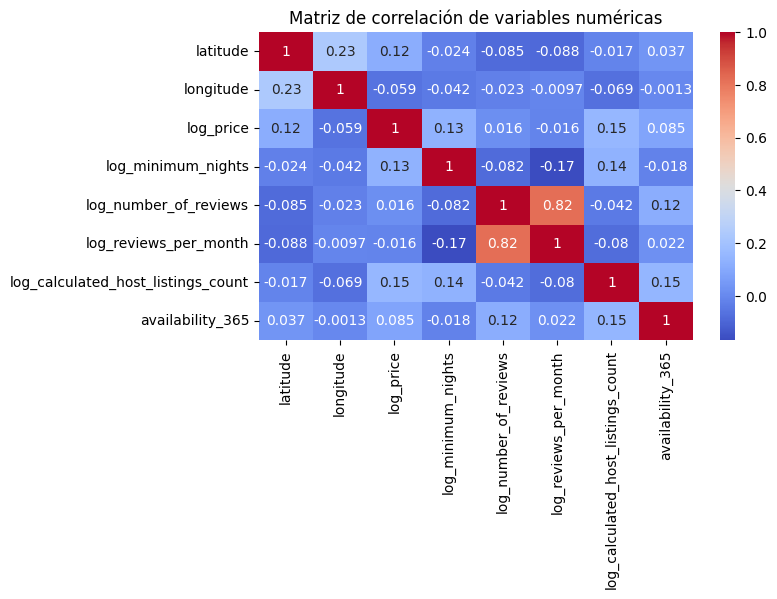

In [19]:
plt.figure(figsize=(7,4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Matriz de correlación de variables numéricas")
plt.show()


Los valores cercanos a 1 o -1 reflejan correlaciones fuertes, mientras que los valores próximos a 0 indican ausencia de relación lineal.

En este caso, se observa una correlación positiva muy alta entre *log_number_of_reviews* y *log_reviews_per_month* (0.82). Tiene sentido, ya que es la misma información pero expresada en términos totales y por mes, es información redundante.

Por otro lado, *latitude* y *longitude* muestran una correlación relativamente moderada (0.23). También tiene sentido al tratarse de ubicaciones.

También se aprecian correlaciones positivas más débiles entre *log_calculated_host_listings_count* y *availability_365* (0.15),
*log_price* y *log_calculated_host_listings_count* (0.15),
*log_calculated_host_listings_count* y *log_minimum_nigths* (0.14),
*log_price* y *log_minimum_nights* (0.13), *log_price* y *latitude* (0.12) y *log_number_of_reviews* y *availability_365* (0.12)

Por último, se observa una correlación negativa débil entre *log_minimum_nights* y *log_reviews_per_month* (-0.17)

En términos generales, la correlación entre las variables tiende a ser baja, siendo la más preocupante la de *log_number_of_reviews* y *log_reviews_per_month*. En principio vamos a entrenar los diferentes modelos con todas las variables y después veremos si mejora o empeora su rendimiento prescindiendo de las que parecen más redundantes.

A continuación dibujamos algunos gráficos de dispersión, segmentados por la variable *room_type*.

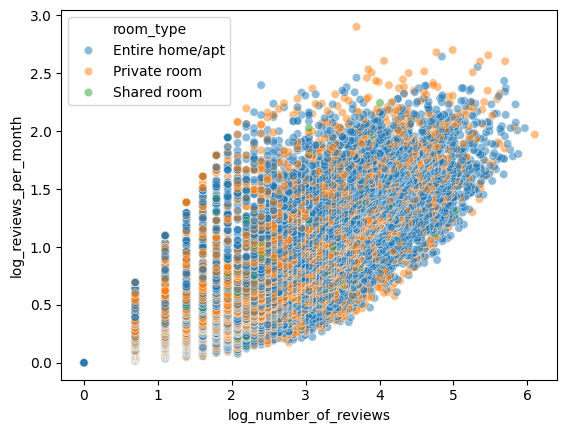

In [20]:
sns.scatterplot(data=alquileres, x='log_number_of_reviews', y='log_reviews_per_month', hue='room_type', alpha=0.5)
plt.show()

Como ya hemos visto en la matriz de correlación, *log_number_of_reviews* y *log_reviews_per_month* tienen una relación lineal muy fuerte. También se aprecia que predominan los apartamentos enteros (puntos azules), mientras que las habitaciones privadas aparecen en menor proporción (puntos naranjas) y las habitaciones compartidas (puntos verdes) apenas se dejan ver.

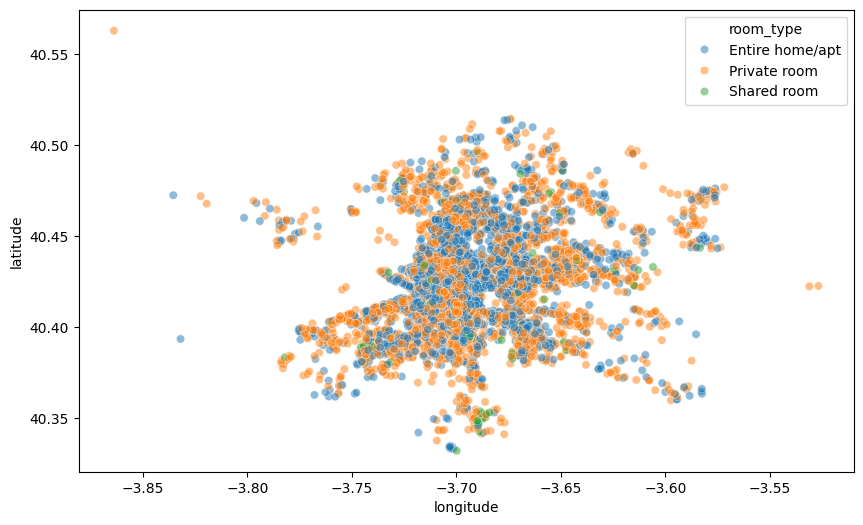

In [21]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=alquileres, x='longitude', y='latitude', hue='room_type', alpha=0.5)
plt.show()

Al representar la *latitude* frente a la *longitude* obtenemos una especie de mapa donde vemos la ubicación de los diferentes tipos de habitaciones. Se aprecia que en el centro hay mayor proporción de ofertas de apartamentos completos (puntos azules), mientras que las habitaciones privadas (puntos naranjas) se concentran más a las afueras. Las habitaciones compartidas (puntos verdes) están más dispersas y también se ven muy pocas.

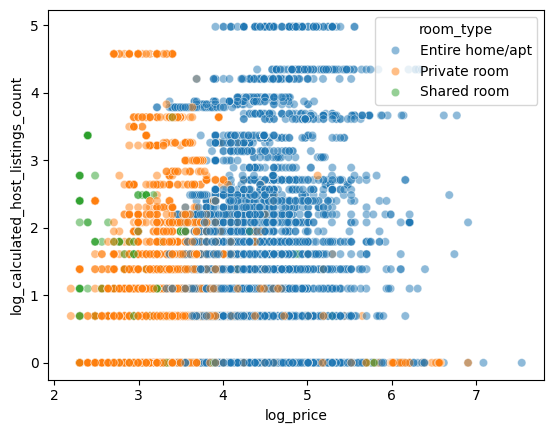

In [22]:
sns.scatterplot(data=alquileres, x='log_price', y='log_calculated_host_listings_count', hue='room_type', alpha=0.5)
plt.show()

La dispersión entre *log_price* y *log_calculated_host_listings_count* es muy grande. Además, se aprecia que los apartamentos enteros predominan en los precios más altos y en los anfitriones con más propiedades, mientras que las habitaciones privadas tienen precios más bajos y sus anfitriones no tienen tantas propiedades. También se aprecia que los precios más bajos son los de las habitaciones compartidas.

Por último observamos la relación entre la variable categórica *neighbourhood_group* y la variable objetivo.

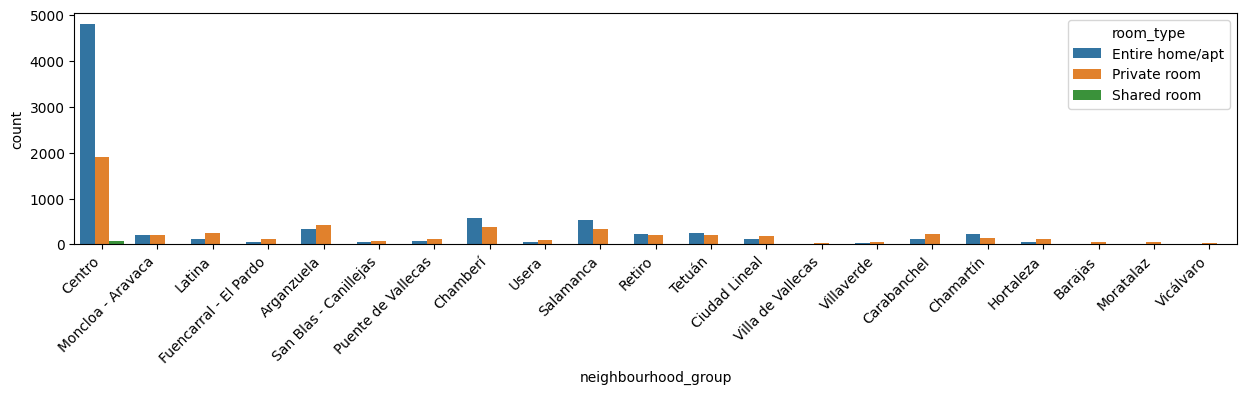

In [23]:
plt.figure(figsize=(15,3))
sns.countplot(data=alquileres, x='neighbourhood_group', hue='room_type')
plt.xticks(rotation=45, ha='right')
plt.show()

Como ya hemos visto la gran mayoría de alojamientos se ubican en el distrito Centro, destacando la categoría de apartamento entero, y en menor medida habitación privada. Además, es el único distrito que tiene ofertas de habitaciones compartidas, aunque muy pocas.

Antes de realizar la división de datos, nos quedamos con las variables que vamos a usar, es decir, las categóricas y las numéricas transformadas:

In [24]:
variables_def = ['latitude', 'longitude','log_price', 'log_minimum_nights', 'log_number_of_reviews',
            'log_reviews_per_month', 'log_calculated_host_listings_count', 'availability_365', 'neighbourhood', 'neighbourhood_group', 'room_type']

**DIVISÓN DE LOS DATOS EN ENTRENAMIENTO Y PRUEBA**

In [25]:
alquileres = alquileres[variables_def]

Dividimos el conjunto de datos en entrenamiento y prueba, asignando un 80 % de los datos al conjunto de entrenamiento y un 20 % al conjunto de prueba. Con random_state fijamos una semilla y con stratify indicamos que en los dos conjuntos asigne la misma proporción de clases de *room_type*, ya que al estar desbalanceada algunas categorías podrían quedar desproporcionadas.

In [26]:
alquileres_train, alquileres_test = train_test_split(alquileres, test_size=0.2, random_state=42, stratify = alquileres["room_type"])

In [27]:
len(alquileres_train)

10652

In [28]:
len(alquileres_test)

2664

Del total de 13321 filas, 10656 se han asignado al conjunto de entrenamiento y 2665 al conjunto de prueba.

Separamos los datos de las variables explicativas (todas excepto *room_type*) de los datos de la variable objetivo (*room_type*), tanto en el conjunto de entrenamiento como en el de prueba:

In [29]:
X_train = alquileres_train.drop('room_type', axis=1)
y_train = alquileres_train['room_type']

X_test = alquileres_test.drop('room_type', axis=1)
y_test = alquileres_test['room_type']

**MODELADO Y EVALUACIÓN**

**Escalado de variables numéricas y transformación de variables categóricas**

Como hemos apreciado anteriormente, las variables numéricas se miden en escalas muy diferentes, por lo que es conveniente aplicar algún tipo de escalado. Dado que no hemos coseguido corregir el sesgo en algunas de las variables numéricas, emplearemos RobustScaler en lugar de StandardScaler, ya que se basa en la mediana y el rango intercuartílico, lo que reduce la influencia de los valores atípicos.

Para las variables categóricas *neighbourhood_group* y *neighbourhood*, aplicaremos OneHotEncoder. Esto significa que transformaremos cada categoría en una nueva variable dicotómica, donde un valor de 1 indica que la fila pertenece a esa categoría y un valor de 0 indica que no. Hay que tener en cuenta, que al haber bastantes categorías en *neighbourhood*, se van a crear muchas columnas.

Con ColumnTransformer creamos las transformaciones comentadas. En OneHotEncoder indicamos que elimine la primera categoría para no tener multicolinealidad (drop = 'first') y con handle_unknown = 'ignore' gestionamos la aparición de nuevas categorías.

In [30]:
categoricas = ['neighbourhood_group', 'neighbourhood']

preprocessor = ColumnTransformer(transformers=[
    ('robust', RobustScaler(), numeric_cols_con_log),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categoricas)
])

Estas transformaciones son las que a priori parecen que mejor van a funcionar atendiendo a las características observadas, pero no tienen por qué dar los mejores resultados. En el siguiente apartado compararemos el rendimiento obtenido con diferentes tipos de transformaciones.

**Entrenamiento de los modelos**

En primer lugar, evaluamos el rendimiento de los tres modelos con todas las variables empleando las transformaciones mencionadas.
Como nuestra variable objetivo presenta clases desbalanceadas empleamos los paramétros class_weigth='balanced' para el Árbol de decisión y weights='distance' para KNN.
Dado que nuestros datos son mayoritariamente númericos, a pesar de que no sigan una distribución normal la gran mayoría, vamos a emplear Gaussian para Naive Bayes.

Creamos el pipeline para cada modelo, indicando el preprocessor con las transformaciones anteriores y el modelo que queremos aplicar.

In [31]:
pipeline_arbol = Pipeline([('preprocessor', preprocessor),
 ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

pipeline_knn = Pipeline([ ('preprocessor', preprocessor), ('classifier', KNeighborsClassifier(weights='distance')) ])
pipeline_nb = Pipeline([ ('preprocessor', preprocessor), ('classifier', GaussianNB()) ])

Llevamos a cabo una validación cruzada con 10 particiones (cv=10) para evaluar la precisión media obtenida en las distintas particiones.

In [32]:
result_arbol = cross_val_score(pipeline_arbol, X_train, y_train, cv=10, scoring='accuracy')
print("Árbol de decisión: Accuracy medio =", result_arbol.mean())

result_knn = cross_val_score(pipeline_knn, X_train, y_train, cv=10, scoring='accuracy')
print("KNN: Accuracy medio =", result_knn.mean())

result_nb = cross_val_score(pipeline_nb, X_train, y_train, cv=10, scoring='accuracy')
print("Naive Bayes Gaussiano: Accuracy medio =", result_nb.mean())

Árbol de decisión: Accuracy medio = 0.8539227862484478
KNN: Accuracy medio = 0.8665968166723921
Naive Bayes Gaussiano: Accuracy medio = 0.1460773018347735


El árbol de decisión y KNN son bastante precisos (85.39% y 86.66% de aciertos respectivamente), mientras que el Naive Bayes Gaussiano obtuvo una precisión muy baja (14.61%),
lo que puede deberse a que muchas de las variables no cumplen el requisito de normalidad que asume el modelo Gaussiano.

Vamos a probar si Naive Bayes mejora empleando MultinomialNB, pero para ello debemos aplicar otro tipo de escalado, como MinMaxScaler, ya que MultinomialNB necesita que los valores no sean negativos y tanto con StandardScaler como con RobustScaler podemos obtener negativos.



In [33]:
preprocessor_multi = ColumnTransformer(transformers=[
    ('scale', MinMaxScaler(), numeric_cols_con_log),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categoricas)
])

pipeline_arbol_multi = Pipeline([('preprocessor_multi', preprocessor_multi),
 ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

pipeline_knn_multi = Pipeline([ ('preprocessor_multi', preprocessor_multi), ('classifier', KNeighborsClassifier(weights='distance')) ])
pipeline_nb_multi = Pipeline([ ('preprocessor_multi', preprocessor_multi), ('classifier', MultinomialNB()) ])

result_arbol_multi = cross_val_score(pipeline_arbol_multi, X_train, y_train, cv=10, scoring='accuracy')
print("Árbol de decisión: Accuracy medio =", result_arbol_multi.mean())

result_knn_multi = cross_val_score(pipeline_knn_multi, X_train, y_train, cv=10, scoring='accuracy')
print("KNN: Accuracy medio =", result_knn_multi.mean())

result_nb_multi = cross_val_score(pipeline_nb_multi, X_train, y_train, cv=10, scoring='accuracy')
print("Naive Bayes Multinomial: Accuracy medio =", result_nb_multi.mean())

Árbol de decisión: Accuracy medio = 0.8538289776180535
KNN: Accuracy medio = 0.8146819755304812
Naive Bayes Multinomial: Accuracy medio = 0.6572449330127104


La precisión del árbol de decisión se mantiene igual, lo que nos indica que el tipo de escalado no influye en su rendimiento.

El rendimiento de KNN empeora ligeramente al usar MinMaxScaler en comparación con RobustScaler (de 86.66% a 81.47%).

Por último, en Naive Bayes observamos mejoras significativas en la precisión empleando MultinomialNB en comparación con GaussianNB (de un 14.61% a un 65.72%). Sin embargo, sigue sin tener buena precisión.

Por último, vamos a probar si Naive Bayes mejora empleando CategoricalNB. Para este tipo de modelo es necesario que las variables sean categóricas, asignando un valor numérico a cada categoría. Primero vamos a emplear solo las variables categóricas junto con OneHotEncoder y después probaremos con todas las variables discretizando las numéricas.

In [34]:
preprocessor_cat = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)
], remainder='drop')

pipeline_arbol_cat = Pipeline([('preprocessor_cat', preprocessor_cat),
 ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

pipeline_knn_cat = Pipeline([ ('preprocessor_cat', preprocessor_cat), ('classifier', KNeighborsClassifier(weights='distance')) ])
pipeline_nb_cat = Pipeline([ ('preprocessor_cat', preprocessor_cat), ('classifier', CategoricalNB(alpha=1.0)) ])

result_arbol_cat = cross_val_score(pipeline_arbol_cat, X_train, y_train, cv=10, scoring='accuracy')
print("Árbol de decisión: Accuracy medio =", result_arbol_cat.mean())

result_knn_cat = cross_val_score(pipeline_knn_cat, X_train, y_train, cv=10, scoring='accuracy')
print("KNN: Accuracy medio =", result_knn_cat.mean())

result_nb_cat = cross_val_score(pipeline_nb_cat, X_train, y_train, cv=10, scoring='accuracy')
print("Naive Bayes Categorical: Accuracy medio =", result_nb_cat.mean())

Árbol de decisión: Accuracy medio = 0.5711576777739609
KNN: Accuracy medio = 0.6343395960503483
Naive Bayes Categorical: Accuracy medio = 0.6416601925499211


Tanto el árbol de decisión como KNN se ven muy afectados en su rendimiento al perder las variables numéricas, ya que seguramente estas eran las que más información aportaban al modelo.
En Naive Bayes Categorical se consiguen resultados ligeramente inferiores que con MultinomialNB.

A continuación transformamos a categóricas las variables numéricas, asignando 5 grupos (n_bins = 5) mediante cuantiles (strategy='quantile'):

In [35]:
preprocessor_cat2 = ColumnTransformer(transformers=[
    ('num', KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile'), numeric_cols_con_log),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)
])

pipeline_arbol_cat2 = Pipeline([('preprocessor_cat2', preprocessor_cat2),
 ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

pipeline_knn_cat2 = Pipeline([ ('preprocessor_cat2', preprocessor_cat2), ('classifier', KNeighborsClassifier(weights='distance')) ])
pipeline_nb_cat2 = Pipeline([ ('preprocessor_cat2', preprocessor_cat2), ('classifier', CategoricalNB()) ])

result_arbol_cat2 = cross_val_score(pipeline_arbol_cat2, X_train, y_train, cv=10, scoring='accuracy')
print("Árbol de decisión: Accuracy medio =", result_arbol_cat2.mean())

result_knn_cat2 = cross_val_score(pipeline_knn_cat2, X_train, y_train, cv=10, scoring='accuracy')
print("KNN: Accuracy medio =", result_knn_cat2.mean())

result_nb_cat2 = cross_val_score(pipeline_nb_cat2, X_train, y_train, cv=10, scoring='accuracy')
print("Naive Bayes Categorical: Accuracy medio =", result_nb_cat2.mean())

Árbol de decisión: Accuracy medio = 0.8437854645068661
KNN: Accuracy medio = 0.8703517163015617
Naive Bayes Categorical: Accuracy medio = 0.8042614662332973


El árbol de decisión pierde algo de precisión frente a los dos primeros modelos en los que se usaban todas las variables (de 85.39% a 84.38%), aunque no es mucha diferencia.

KNN consigue mejorar de un 86.66% en el primer modelo a un 87.04% en este.

Naive Bayes Categorical con las variables numéricas discretizadas es en el que mejores resultados ofrece en comparación con Gaussian y Multinomial, aumentando la precisión hasta un 80.43%.

En términos generales, las precisiones mejoran introduciendo las variables numéricas. Si se discretizan es cuando obtenemos los mejores resultados para KNN y Naive Bayes Categorical, mientras que el árbol funciona ligeramente mejor sin discretizar, independientemente del tipo de escalado.


**Resultados**

In [36]:
resumen = {
    "Transformación": [
        "RobustScaler + OneHotEncoder",
        "MinMaxScaler + OneHotEncoder",
        "OneHotEncoder",
        "OneHotEncoder + KBins numéricas"
    ],
    "Árbol": [85.39, 85.38, 57.12, 84.38],
    "KNN": [86.66, 81.47, 63.43, 87.04],
    "Naive Bayes": [
      "14.61 (GaussianNB)",
        "65.72 (MultinomialNB)",
        "64.17 (CategoricalNB)",
        "80.43 (CategoricalNB)"
    ]
}

resultados = pd.DataFrame(resumen)
print(tabulate(resultados, headers='keys', tablefmt='fancy_grid', showindex=False))


╒═════════════════════════════════╤═════════╤═══════╤═══════════════════════╕
│ Transformación                  │   Árbol │   KNN │ Naive Bayes           │
╞═════════════════════════════════╪═════════╪═══════╪═══════════════════════╡
│ RobustScaler + OneHotEncoder    │   85.39 │ 86.66 │ 14.61 (GaussianNB)    │
├─────────────────────────────────┼─────────┼───────┼───────────────────────┤
│ MinMaxScaler + OneHotEncoder    │   85.38 │ 81.47 │ 65.72 (MultinomialNB) │
├─────────────────────────────────┼─────────┼───────┼───────────────────────┤
│ OneHotEncoder                   │   57.12 │ 63.43 │ 64.17 (CategoricalNB) │
├─────────────────────────────────┼─────────┼───────┼───────────────────────┤
│ OneHotEncoder + KBins numéricas │   84.38 │ 87.04 │ 80.43 (CategoricalNB) │
╘═════════════════════════════════╧═════════╧═══════╧═══════════════════════╛


En esta tabla tenemos un resumen de los resultados obtenidos con cada combinación de transformaciones.


*  Árbol de decisión: no se ve influenciado por el tipo de escalado, pero sí necesita conservar las variables numéricas.  Tiene rendimientos similares con casi todas las transformaciones (84-85% de precisión), excepto al eliminar la información numérica.


*   KNN: Funciona mejor con escalado o discretización (87% de precisión), ya que trabaja con distancias. También necesita tener en cuenta las variables numéricas.


*  Naive Bayes: GaussianNB falla (14.61%) porque las variables no siguen normalidad. MultinomialNB mejora mucho (65.72%) al trabajar con valores discretos. CategoricalNB con discretización de numéricas alcanza un 80.43% de presición, siendo la más adecuada.





En base a estos resultados, vamos a seleccionar la transformación OneHotEncoder + KBinsDiscretizer como preprocesamiento, ya que ofrece un rendimiento equilibrado entre los tres algoritmos.

Ya hemos decidido las transformaciones que mejores resultados dan, pero vimos anteriormente que las variables *log_number_of_reviews* y *log_reviews_per_month* estaban muy relacionadas. Vamos a evaluar el rendimiento de los modelos con las transformaciones decididas prescindiendo de la variable *log_reviews_per_month*:

In [40]:
numeric_cols_con_log_mod = [col for col in numeric_cols_con_log if col != 'log_reviews_per_month']

X_train_mod = X_train.drop(columns=['log_reviews_per_month'])

preprocessor_cat3 = ColumnTransformer(transformers=[
    ('num', KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile'), numeric_cols_con_log_mod),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)
])

pipeline_arbol_cat3 = Pipeline([('preprocessor_cat3', preprocessor_cat3),
 ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

pipeline_knn_cat3 = Pipeline([ ('preprocessor_cat3', preprocessor_cat3), ('classifier', KNeighborsClassifier(weights='distance')) ])
pipeline_nb_cat3 = Pipeline([ ('preprocessor_cat3', preprocessor_cat3), ('classifier', CategoricalNB()) ])

result_arbol_cat3 = cross_val_score(pipeline_arbol_cat3, X_train_mod, y_train, cv=10, scoring='accuracy')
print("Árbol de decisión: Accuracy medio =", result_arbol_cat3.mean())

result_knn_cat3 = cross_val_score(pipeline_knn_cat3, X_train_mod, y_train, cv=10, scoring='accuracy')
print("KNN: Accuracy medio =", result_knn_cat3.mean())

result_nb_cat3 = cross_val_score(pipeline_nb_cat3, X_train_mod, y_train, cv=10, scoring='accuracy')
print("Naive Bayes Categorical: Accuracy medio =", result_nb_cat3.mean())

Árbol de decisión: Accuracy medio = 0.8405938570761655
KNN: Accuracy medio = 0.8646256022690236
Naive Bayes Categorical: Accuracy medio = 0.8049185670621603


Los resultados se mantienen similares, incluso algo más bajos, por lo que vamos a seguir mantiendo la variable *log_reviews_per_month*

**Afinación de hiperparámetros**

Con el objetivo de intentar mejorar el rendimiento de los modelos KNN y Árbol de decisión vamos a realizar una afinación de hiperparámetros. Para realizar las evaluaciones, también empleamos validación cruzada con 10 particiones.

Tanto para KNN como para el árbol  empleamos la transformación de OneHotEncoder + KBins numéricas.



*   KNN: buscamos el valor óptimo de número de vecinos más cercanos (k).



In [41]:
param_knn = {'classifier__n_neighbors': list(range(1, 31))}

grid_knn = GridSearchCV(pipeline_knn_cat2, param_knn, cv=10, scoring='accuracy')
grid_knn.fit(X_train, y_train)

best_index = grid_knn.best_index_

mean_accuracy = grid_knn.cv_results_['mean_test_score'][best_index]
print("Mejor KNN: ", grid_knn.best_params_)
print("Accuracy medio: ", mean_accuracy)


Mejor KNN:  {'classifier__n_neighbors': 21}
Accuracy medio:  0.8803024777810075


Se observa que al aumentar el número de vecinos de k = 5 a k = 21, el modelo KNN mejora ligeramente su rendimiento, pasando de una precisión del 87.04% al 88.03%. El modelo se beneficia al considerar un mayor número de vecinos, probablemente debido a la discretización de las variables numéricas.



*  Árbol de decisión: buscamos los valores más óptimos variando el número de hojas entre 2 y 50, el mínimo número de muestras entre 2 y 6 y la profundidad máxima del árbol entre 1 y 20.


In [42]:
param_tree = {
    'classifier__max_leaf_nodes': list(range(2, 51)),
    'classifier__min_samples_split': list(range(2, 7)),
    'classifier__max_depth': list(range(1, 21))
}

grid_arbol = GridSearchCV(
    estimator=pipeline_arbol_cat2,
    param_grid=param_tree,
    cv=10,
    scoring='accuracy',
    n_jobs=-1
)
grid_arbol.fit(X_train, y_train)

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('preprocessor_cat2',
                                        ColumnTransformer(transformers=[('num',
                                                                         KBinsDiscretizer(encode='ordinal'),
                                                                         ['latitude',
                                                                          'longitude',
                                                                          'log_price',
                                                                          'log_minimum_nights',
                                                                          'log_number_of_reviews',
                                                                          'log_reviews_per_month',
                                                                          'log_calculated_host_listings_count',
                                                                          'availability_365']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sp...
                                       ('classifier',
                                        DecisionTreeClassifier(class_weight='balanced',
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                   10, 11, 12, 13, 14, 15, 16,
                                                   17, 18, 19, 20],
                         'classifier__max_leaf_nodes': [2, 3, 4, 5, 6, 7, 8, 9,
                                                        10, 11, 12, 13, 14, 15,
                                                        16, 17, 18, 19, 20, 21,
                                                        22, 23, 24, 25, 26, 27,
                                                        28, 29, 30, 31, ...],
                         'classifier__min_samples_split': [2, 3, 4, 5, 6]},
             scoring='accuracy')

In [43]:
print("Mejores hiperparámetros:", grid_arbol.best_params_)

Mejores hiperparámetros: {'classifier__max_depth': 2, 'classifier__max_leaf_nodes': 3, 'classifier__min_samples_split': 2}


In [44]:
print("Mejor accuracy en validación cruzada:", grid_arbol.best_score_)

Mejor accuracy en validación cruzada: 0.7831449233235561


Se observa que la precisión del árbol de decisión con una profundidad de 2 hojas y 3 nodos es la más óptima, a pesar de obtenerse una precisión algo menor. Esto puede deberse a que antes se estaba sobreajustando demasiado a los datos.

Dibujamos el mejor árbol obtenido:

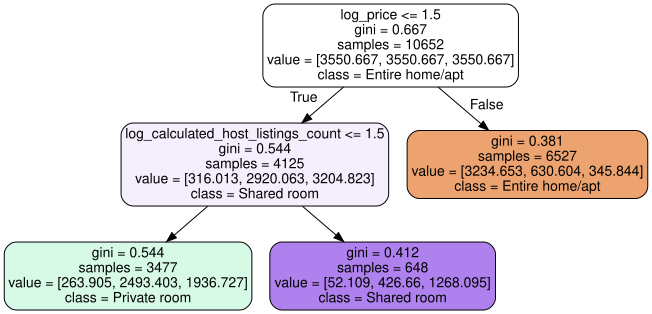

In [47]:
mejor_arbol = grid_arbol.best_estimator_
mejor_arbol_clf = mejor_arbol.named_steps['classifier']
preproc = mejor_arbol.named_steps['preprocessor_cat2']


num_features = list(numeric_cols_con_log)
cat_encoder = preproc.named_transformers_['cat']
cat_features = cat_encoder.get_feature_names_out(categoricas)

feature_names = np.concatenate([num_features, cat_features])

export_graphviz(
    mejor_arbol_clf,
    out_file="airbnb_arbol.dot",
    feature_names=feature_names,
    class_names=sorted(y_train.unique()),
    rounded=True,
    filled=True
)

Source.from_file("airbnb_arbol.dot")


El modelo fue entrenado con un total de 10652 observaciones, utilizando el índice de Gini como criterio de impureza para la clasificación. Entre todas las variables, *log_price* es la que más información aporta al modelo. El índice de Gini inicial es de 0.67, lo que indica una alta mezcla entre clases, siendo la clase dominante la de apartamentos enteros.

Para los casos en los que *log_price* <= 1.5, el árbol realiza una segunda división a través de la variable *log_calculated_host_listings_count*, considerando 4125 observaciones. En este nodo, el índice de Gini baja a 0.544, lo que refleja una mejora en la pureza respecto al nodo anterior. Se observa que los alojamientos más baratos y pertenecientes a anfitriones con pocas propiedades, tienden a ser de habitaciones compartidas (la más predominante en esta rama).

El índice de Gini para la categoría de habitaciones privadas es alto, indicando que no es capaz de clasificar muy bien esta clase.

En cambio, cuando *log_price* > 1.5, se observa una mayor reducción del índice de Gini, indicando que la pureza aumenta en esta rama. La mayoría de los alojamientos en este nodo son clasificados como apartamentos enteros. Esto indica que, a mayor precio, es más probable que se trate de un apartamento completo.

In [48]:
knn_final = grid_knn.best_estimator_
arbol_final = mejor_arbol

Para Naive Bayes, entrenamos el modelo con el pipeline que mejor resultado nos dio anteriormente:

In [49]:
pipeline_nb_cat2.fit(X_train, y_train)
nb_final = pipeline_nb_cat2

**Evaluación de los modelos**

Una vez entrenamos los mejores modelos, el siguiente paso es evaluar cómo funcionan con datos no vistos. Para ello, utilizamos el conjunto de prueba y verificamos si el modelo es capaz de hacer buenas predicciones y en este caso, de distinguir bien entre las diferentes categorías de *room_type*.



*  Árbol de decisión



Accuracy:  0.8314564564564565


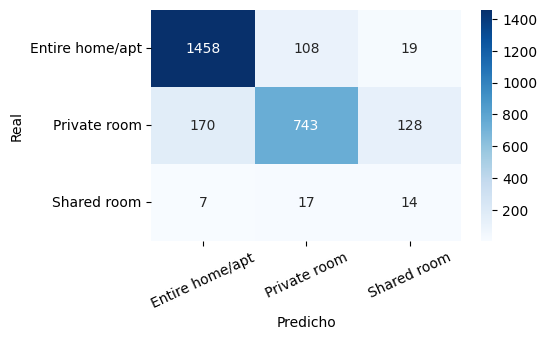

In [55]:
y_pred = arbol_final.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy: ", acc)

etiquetas = ['Entire home/apt', 'Private room', 'Shared room']
cm = confusion_matrix(y_test, y_pred, labels = etiquetas)

plt.figure(figsize=(5,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.xticks(rotation=25)
plt.show()

Con el mejor árbol de decisión se logra una precisión del 83.14% en la predicción de las categorías del conjunto de prueba. En la matriz de confusión se observa cómo el modelo ha clasificado las distintas categorías de alojamiento.

La diagonal principal representa los aciertos. De esta forma, 1458 observaciones que correspondían a apartamentos enteros fueron clasificadas correctamente, mientras que 108 fueron clasificadas incorrectamente como habitaciones privadas y 19 como habitaciones compartidas.

De manera similar, 743 observaciones pertenecientes a habitaciones privadas se clasificaron de forma correcta, mientras que 170 fueron confundidas con apartamentos enteros y 128 con habitacones compartidas.

Por último, solamente 14 observaciones pertenecientes a habitaciones compartidas se clasificaron de forma correcta. La gran mayoría, 17, se confundieron con habitaciones privadas, y 7 con apartamentos enteros. El modelo no es capaz de distinguir muy bien esta categoría.



*   KNN



Accuracy:  0.8787537537537538


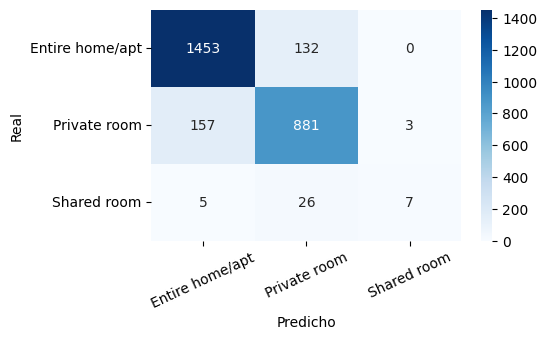

In [57]:
y_pred = knn_final.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy: ", acc)

etiquetas = ['Entire home/apt', 'Private room', 'Shared room']
cm = confusion_matrix(y_test, y_pred, labels = etiquetas)

plt.figure(figsize=(5,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.xticks(rotation=25)
plt.show()

Con KNN utilizando k=21, se consigue un 87.87% de precisión.

Se aprecia que 1453 observaciones que correspondían a apartamentos enteros fueron clasificadas correctamente, mientras que 132 fueron clasificadas incorrectamente como habitaciones privadas y ninguna como habitaciones compartidas.

Por otro lado, 881 observaciones pertenecientes a habitaciones privadas se clasificaron de forma correcta, mientras que 157 fueron confundidas con apartamentos enteros y 3 con habitacones compartidas.

Por último, 7 habitaciones compartidas se clasificaron de forma correcta, mientras que 26 se clasificaron como habitaciones privadas de forma errónea y 5 como apartamentos enteros.

Al igual que en el árbol, la categoría de habitaciones compartidas la confunde mucho con habitaciones privadas.



*   Naive Bayes




Accuracy:  0.8175675675675675


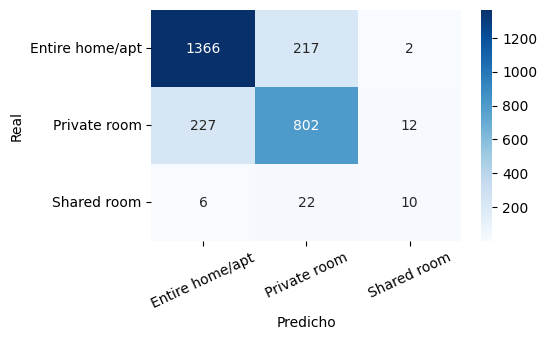

In [59]:
y_pred = nb_final.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Accuracy: ", acc)

etiquetas = ['Entire home/apt', 'Private room', 'Shared room']
cm = confusion_matrix(y_test, y_pred, labels = etiquetas)

plt.figure(figsize=(5,3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=etiquetas, yticklabels=etiquetas)
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.xticks(rotation=25)
plt.show()



Con Naive Bayes Categorical se consigue un 81.76% de precisión.

Se observa que 1366 observaciones que correspondían a apartamentos enteros fueron clasificadas correctamente, mientras que 217 fueron clasificadas incorrectamente como habitaciones privadas y 2 como habitaciones compartidas.

Por otro lado, 802 observaciones pertenecientes a habitaciones privadas se clasificaron de forma correcta, mientras que 227 fueron confundidas con apartamentos enteros y 12 con habitacones compartidas.

Por último, 10 habitaciones compartidas se clasificaron de forma correcta, mientras que 22 se clasificaron como habitaciones privadas y 6 como apartamentos enteros.

Al igual que en el árbol y en KNN, la categoría que mejor predice es la de apartamentos completos, y la que más confunde es la de habitaciones privadas. Es decir, cuanto mayor número de observaciones haya para una categoría, más precisa es la predicción.

Finalmente, el modelo que mejor precisión ofrece es el de KNN con k = 21.

**CONCLUSIONES**

En el análisis exploratorio se observó un fuerte sesgo en las variables numéricas, un desbalance significativo de la variable objetivo *room_type* y una alta correlación entre *reviews_per_month* y *number_of_reviews*.

Tras comparar distintas combinaciones de escalado y codificación, la transformación que mejores rendimientos en términos globales ofreció fue discretizar las variables numéricas y aplicar OneHotEncoder a las variables categóricas. A pesar de la correlación mencionada, mantener todas las variables ofreció un rendimiento ligeramente superior.

Entre los modelos evaluados (KNN, árbol de decisión y Naive Bayes Categorical), dieron mejores resultados KNN y el árbol de decisión.
A continuación, se realizó afinación de hiperparámetros mediante GridSearch. En KNN, el valor óptimo encontrado fue k = 21. En el caso del árbol de decisión, el modelo más eficiente era un árbol con 3 nodos y 2 hojas, donde *price* aparecía como la variable más discriminativa.

En conclusión, KNN se posiciona como el modelo con mejor precisión general (87.87%) a la hora de predecir *room_type*.
Además, los tres modelos presentan dificultad a la hora de clasificar la clase minoritaria (habitaciones compartidas), confundiéndola con la categoría de habitaciones privadas.